06 : Use the K-Means clustering algorithm to segment customers based on their purchasing behavior. Apply the
Elbow Method to determine the optimal number of clusters that best represent distinct customer segments
for targeted marketing strategies. Dataset: UCI Machine Learning Repository - Wholesale Customers Data
Set

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, silhouette_score

In [3]:
df = pd.read_csv('Wholesale_Customers.csv')
print("Dataset Shape :", df.shape)
df.head()

Dataset Shape : (440, 9)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


In [4]:
if df.isnull().sum().sum() > 0:
    print("Missing Values Present")
    print(df.isnull().sum())
else :
    print("No Missing Values Found")

No Missing Values Found


In [5]:
df.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen', 'Cluster'],
      dtype='object')

In [6]:
x = df.drop(['Channel', 'Region'], axis=1)
x.sample(5)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
356,22686,134,218,3157,9,548,1
80,7005,829,3009,430,610,529,1
282,49063,3965,4252,5970,1041,1404,1
106,1454,6337,10704,133,6830,1831,1
77,12205,12697,28540,869,12034,1009,0


In [7]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [8]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(x_scaled)

    wcss.append(kmeans.inertia_)
    
print("\nWCSS Values :")
for k, value in enumerate(wcss, start=1):
    print(f"K = {k}: {value:.2f}")

D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl


WCSS Values :
K = 1: 3080.00
K = 2: 2003.46
K = 3: 1637.09
K = 4: 1346.71
K = 5: 1136.95
K = 6: 989.49
K = 7: 841.33
K = 8: 761.94
K = 9: 682.08
K = 10: 633.71


D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [9]:
scores = []

for k in range(2, 8):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(x_scaled)

    score = silhouette_score(x_scaled, labels)

    scores.append(score)

    print("Clusters:", k, "Silhouette Score:", round(score, 4))

D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Clusters: 2 Silhouette Score: 0.6323
Clusters: 3 Silhouette Score: 0.6385
Clusters: 4 Silhouette Score: 0.4317


D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Clusters: 5 Silhouette Score: 0.411
Clusters: 6 Silhouette Score: 0.3147
Clusters: 7 Silhouette Score: 0.3193


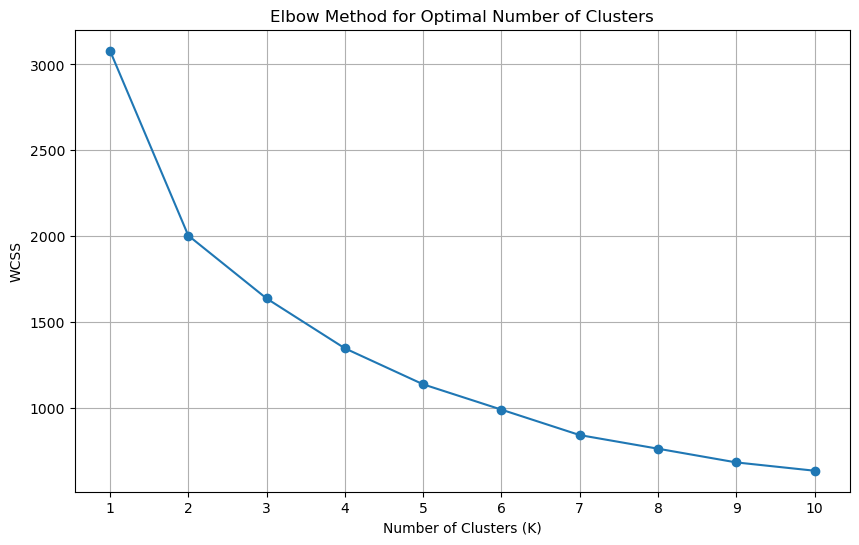

In [39]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [42]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(x_scaled)

print(df[["Channel", "Region", "Cluster"]].head())
print("\nCustomers in each cluster:")
print(df["Cluster"].value_counts())

   Channel  Region  Cluster
0        2       3        1
1        2       3        1
2        2       3        1
3        1       3        1
4        2       3        1

Customers in each cluster:
Cluster
1    394
0     45
2      1
Name: count, dtype: int64


D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


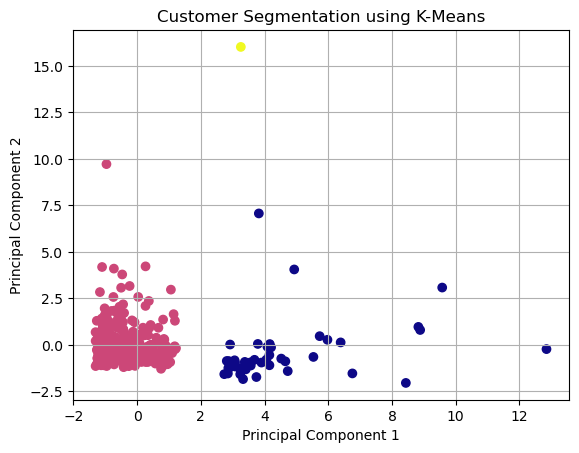

In [54]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(x_scaled)

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Cluster"],
    cmap="plasma"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation using K-Means")
plt.grid()
plt.show()